In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
!pip install -q transformers datasets accelerate evaluate scikit-learn

In [4]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

print(dataset)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [5]:
print(dataset["train"][0])
print("\nLabel:", dataset["train"][0]["label"])

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [9]:
from collections import Counter

print(Counter(dataset["train"]["label"]))
print(Counter(dataset["test"]["label"]))

Counter({0: 12500, 1: 12500})
Counter({0: 12500, 1: 12500})


Step 6: Create Train and Validation Sets
We'll split the original 25,000 training samples into:
- 80% Training: 20,000
- 20% Validation: 5,000

In [10]:
from sklearn.model_selection import train_test_split

train_valid = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42,
    stratify_by_column="label"
)

train_dataset = train_valid["train"]
val_dataset = train_valid["test"]
test_dataset = dataset["test"]

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 20000
Validation: 5000
Test: 25000


Load the DistilBERT Tokenizer
We'll use the pretrained distilbert-base-uncased tokenizer.

The tokenizer converts raw text into numerical token IDs that DistilBERT can process.

What we're doing:
- Loading the pretrained tokenizer.
- Using the same tokenizer associated with DistilBERT.
- Preparing to convert customer reviews into model inputs.

In [11]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(tokenizer)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertTokenizer(name_or_path='distilbert/distilbert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


Understand Tokenization
Before applying tokenization to the entire dataset, let's inspect one review.

Key observations:
- 101 → [CLS] special token.
- Input IDs → Numerical token representations.
- Attention mask → All 1s because no padding was applied.
- 256 tokens → Review was truncated to the specified maximum length.
Note: We'll apply padding when processing batches so that all sequences have equal length.

In [12]:
sample_text = train_dataset[0]["text"]

tokens = tokenizer(
    sample_text,
    truncation=True,
    max_length=256
)

print("Input IDs:", tokens["input_ids"][:20])
print("Attention Mask:", tokens["attention_mask"][:20])
print("Number of tokens:", len(tokens["input_ids"]))

Input IDs: [101, 2044, 3752, 6197, 1997, 2204, 4391, 2055, 2023, 3185, 1045, 2787, 2000, 2202, 2009, 2005, 1037, 6714, 1006, 1045]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Number of tokens: 256


In [15]:
tokens = ["[CLS]", "this", "movie", "is", "excellent", "[SEP]"]

print(tokenizer.convert_tokens_to_ids(tokens))

## Important: These IDs are fixed in the pretrained tokenizer's vocabulary. They are not randomly generated for each review.

[101, 2023, 3185, 2003, 6581, 102]


Tokenize the Entire Dataset
Now we'll apply the tokenizer to all three splits

In [13]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256
    )

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Apply Dynamic Padding and Create DataLoaders
We'll use Hugging Face's DataCollatorWithPadding to dynamically pad sequences within each batch.

Purpose:
- Dynamic padding: Pads sequences to the longest sequence in each batch.
- DataLoader: Loads data in batches.
- Batch size: 16.
- shuffle=True: Shuffles training data between epochs.

In [16]:
from transformers import DataCollatorWithPadding
from torch.utils.data import DataLoader

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

train_dataset = train_dataset.rename_column("label", "labels")
val_dataset = val_dataset.rename_column("label", "labels")
test_dataset = test_dataset.rename_column("label", "labels")

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
test_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True, collate_fn=data_collator
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, collate_fn=data_collator
)

test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False, collate_fn=data_collator
)

Load Pretrained DistilBERT Model
We'll load DistilBERT with a sequence classification head for 2 classes (Positive and Negative)

In [17]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [18]:
## move the model to GPU

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("Device:", device)

Device: cuda


Configure Optimizer and Learning Rate Scheduler
We'll use AdamW optimizer with a linear learning rate scheduler.

In [19]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

EPOCHS = 3
LEARNING_RATE = 2e-5

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=total_steps
)

print("Total training steps:", total_steps)

Total training steps: 3750


Model Training and Validation
Now we'll implement the training loop.

We'll train for 3 epochs and evaluate on the validation set after every epoch.

In [21]:
import copy

# Reset model to pretrained weights
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2
).to(device)

optimizer = AdamW(
    model.parameters(), lr=2e-5, weight_decay=0.01
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=len(train_loader) * EPOCHS
)

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    model.train()
    total_train_loss = 0

    for batch in tqdm(train_loader):

        batch = {k: v.to(device) for k, v in batch.items()}

        optimizer.zero_grad()
        outputs = model(**batch)
        loss = outputs.loss

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

    # Validation
    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            total_val_loss += outputs.loss.item()

    avg_val_loss = total_val_loss / len(val_loader)

    print(f"Epoch {epoch+1}: Validation Loss = {avg_val_loss:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "best_distilbert_model.pt"
        )

        print("Best model checkpoint saved!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1250 [00:00<?, ?it/s]

Epoch 1: Validation Loss = 0.2622
Best model checkpoint saved!


  0%|          | 0/1250 [00:00<?, ?it/s]

Epoch 2: Validation Loss = 0.3142


  0%|          | 0/1250 [00:00<?, ?it/s]

Epoch 3: Validation Loss = 0.3723


Load the best checkpoint
Now we will load the model weights saved from Epoch 1 and use them for final evaluation.

In [22]:
import torch
from transformers import AutoModelForSequenceClassification

# Load the model architecture
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# Load the best saved weights
model.load_state_dict(
    torch.load("best_distilbert_model.pt", map_location=device)
)

# Move model to GPU
model.to(device)

# Set evaluation mode
model.eval()

print("Best model loaded successfully!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Best model loaded successfully!


Evaluate on the test dataset
Now we evaluate the model on the untouched 25,000-record test dataset.

In [23]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

model.eval()

test_predictions = []
test_actual = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Test Evaluation"):

        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)

        preds = torch.argmax(outputs.logits, dim=1)

        test_predictions.extend(preds.cpu().numpy())
        test_actual.extend(batch["labels"].cpu().numpy())

accuracy = accuracy_score(test_actual, test_predictions)

precision, recall, f1, _ = precision_recall_fscore_support(
    test_actual,
    test_predictions,
    average="binary"
)

print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")

Test Evaluation:   0%|          | 0/1563 [00:00<?, ?it/s]

Test Accuracy:  0.9039
Test Precision: 0.9293
Test Recall:    0.8743
Test F1-score:  0.9010


[[11668   832]
 [ 1571 10929]]


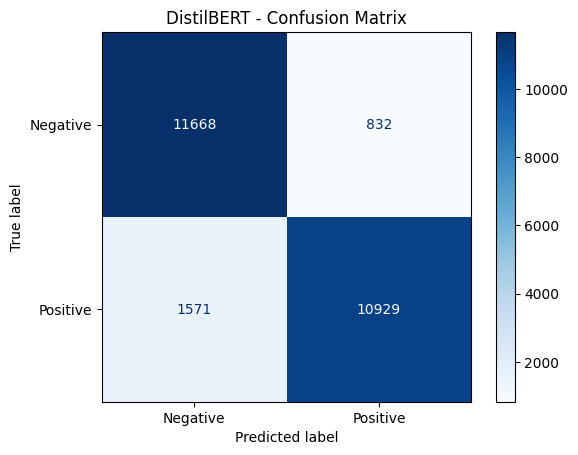

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(test_actual, test_predictions)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT - Confusion Matrix")
plt.show()

Save the fine-tuned model and tokenizer
First, save both locally in your Colab session. We can upload them to Hugging Face Hub later and link the model from your GitHub repository.

- Model configuration (config.json)
- Fine-tuned weights (model.safetensors)
- Tokenizer vocabulary and configuration files
Important: These files are currently stored in Colab's temporary storage. They will disappear if the runtime is deleted.

In [25]:
import os

SAVE_DIR = "/content/distilbert_sentiment_model"

os.makedirs(SAVE_DIR, exist_ok=True)

# Save fine-tuned model
model.save_pretrained(SAVE_DIR)

# Save tokenizer
tokenizer.save_pretrained(SAVE_DIR)

print("Model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!


Install Git LFS in Google Colab
Now we need Git LFS to upload the large model weights to GitHub.

In [27]:
!apt-get update -qq
!apt-get install git-lfs -y -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package git-lfs.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [28]:
!git lfs install

Git LFS initialized.


Configure Git identity
Run this cell, replacing the values with your GitHub username and the email associated with your GitHub

In [29]:
!git config --global user.name "Debangshu-kgpian"
!git config --global user.email "debangshu.bose789@gmail.com"

Clone your GitHub repository into Colab
Clone the Colab workspace to Gitgub repository

In [30]:
!git clone https://github.com/Debangshu-kgpian/customer-review-sentiment-classification.git

Cloning into 'customer-review-sentiment-classification'...


In [31]:
%cd customer-review-sentiment-classification

/content/customer-review-sentiment-classification


Configure Git LFS to track model weights

In [32]:
!git lfs track "*.safetensors"

Tracking "*.safetensors"


In [33]:
!cat .gitattributes

*.safetensors filter=lfs diff=lfs merge=lfs -text


Copy the model into your GitHub repository

In [34]:
import shutil
import os

shutil.copytree(
    "/content/distilbert_sentiment_model",
    "model",
    dirs_exist_ok=True
)

print(os.listdir("model"))

['model.safetensors', 'config.json', 'tokenizer.json', 'tokenizer_config.json']


Verify Git LFS tracking

In [35]:
!git lfs status


Objects to be committed:


Objects not staged for commit:




In [36]:
!git status

On branch main

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitattributes
	model/

nothing added to commit but untracked files present (use "git add" to track)


In [37]:
!git add .gitattributes model/

In [38]:
!git status

On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   .gitattributes
	new file:   model/config.json
	new file:   model/model.safetensors
	new file:   model/tokenizer.json
	new file:   model/tokenizer_config.json



In [39]:
!git commit -m "Add fine-tuned DistilBERT model and tokenizer"

[main (root-commit) 31079de] Add fine-tuned DistilBERT model and tokenizer
 5 files changed, 30723 insertions(+)
 create mode 100644 .gitattributes
 create mode 100644 model/config.json
 create mode 100644 model/model.safetensors
 create mode 100644 model/tokenizer.json
 create mode 100644 model/tokenizer_config.json


Push to GitHub.

In [40]:
!git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [41]:
from getpass import getpass
import subprocess

token = getpass("Enter your GitHub Personal Access Token: ")

remote_url = "https://Debangshu-kgpian:" + token + "@github.com/Debangshu-kgpian/customer-review-sentiment-classification.git"

subprocess.run(
    ["git", "remote", "set-url", "origin", remote_url],
    check=True
)

print("GitHub authentication configured.")

Enter your GitHub Personal Access Token: ··········
GitHub authentication configured.


Upload model and tokenizer

In [42]:
!git push -u origin main

Uploading LFS objects: 100% (1/1), 268 MB | 38 MB/s, done.
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 204.28 KiB | 5.52 MiB/s, done.
Total 8 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/Debangshu-kgpian/customer-review-sentiment-classification.git
 * [new branch]      main -> main
branch 'main' set up to track 'origin/main'.
